<img src="source/AndrejKarpathy.jpg" alt="Andrej Karpathy" width="160">

这次分享内容的主干来自 Andrej Karpathy 的课程 [Neural Networks: Zero to Hero](https://www.youtube.com/watch?v=VMj-3S1tku0&list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&index=1)，一部分来自大模型的补充。

# 训练好的模型本质上是一个函数

一个训练好的大模型，本质上就是一个函数：给定输入，按一套已经定好的计算，得到输出。

$$
y = f(x;\ \theta)
$$

- $x$：输入。一个数、一句话、一张图，都可以是 $x$。
- $\theta$：参数，也就是权重和偏置。这些数决定函数的具体形状。
- $y$：输出。比如类别、下一个字，或者一个数值。

神经网络是把加法、乘法和激活函数（比如 tanh）嵌套、组合成一个函数 $f$。

函数由结构和参数组成。看一个具体的函数：

$$
f(x) = ax^2 + bx + c
$$

这是一个一元二次函数：只有一个输入 $x$，最高次是 $x^2$。这里讨论的就是函数的结构。它约定了这个函数做什么计算操作。

参数是里面可以改的数：$a$、$b$、$c$。取 $a = 3$、$b = -4$、$c = 5$，就得到

$$
f(x) = 3x^2 - 4x + 5
$$

结构没有变，换一组 $a, b, c$，曲线就不一样。



类似的，大模型也能分成结构和参数两部分。

结构就是模型的架构：用不用 Transformer，有多少层、每层多宽、有多少个注意力头，词怎么变成向量，注意力、前馈网络、残差怎么接。这些在训练之前就定好，训练过程中通常不动。

<img src="source/transformer_figure1.png" alt="Transformer 模型架构" width="420">

图 1：Transformer 的模型结构。引自 Vaswani et al., *Attention Is All You Need*, NIPS 2017, Figure 1.

参数就是每个计算层中的权重，大模型训练就是在调整参数。

# 大模型训练
训练要解决两件事：1、评判这组参数 “好不好”；2、判断每个参数该往哪个方向改进。

## background
从美国的政府网站上捞了3.2万个最常用的英文名，作为训练数据。训练一个取英文名的模型。

模型的输入是前几个英文字母，输出是下一个字母。


In [ ]:
"""
emma
olivia
ava
isabella
sophia
charlotte

......
"""

In [ ]:
"""
dontell
khylum
camatena
aeriline
najlah
sherrith
ryel
irmi
taislee
mortaz
akarli
maxfelynn
biolett
zendy

......
"""

## 损失函数
如果去掉激活层，模型的预测结果其实是一个概率向量。

比如说我们现在要让大模型根据 "emm" 预测下一个字母

In [3]:
import torch

logits = torch.tensor([6.37162971496582, 10.324345588684082, -2.457840919494629, -0.6321395635604858, 0.7928482294082642, 9.496803283691406, -21.189800262451172, -12.472290992736816, -0.1473088264465332, 9.046394348144531, 0.8408803939819336, -3.6488943099975586, -0.30528903007507324, -1.0500564575195312, 1.1639387607574463, 7.706233024597168, 2.9873945713043213, -8.511284828186035, 5.047435283660889, -2.1477763652801514, 4.842886447906494, 6.437710762023926, -1.398013949394226, 2.3321409225463867, -17.720596313476562, 8.629511833190918, -5.485987663269043])

# softmax：e^{z_i} / sum_j e^{z_j}，把 logits 收成概率向量
probs = torch.softmax(logits, dim=0)

# ['.', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
probs

tensor([9.4938e-03, 4.9441e-01, 1.3895e-06, 8.6247e-06, 3.5860e-05, 2.1612e-01,
        1.0178e-14, 6.2177e-11, 1.4006e-05, 1.3775e-01, 3.7624e-05, 4.2226e-07,
        1.1959e-05, 5.6786e-06, 5.1972e-05, 3.6062e-02, 3.2187e-04, 3.2649e-09,
        2.5255e-03, 1.8946e-06, 2.0583e-03, 1.0142e-02, 4.0098e-06, 1.6715e-04,
        3.2683e-13, 9.0788e-02, 6.7258e-08])

In [4]:
# 正确答案的概率向量，这是一个 One-Hot 向量
result = torch.tensor([0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=torch.float)

# 对应位置相乘再相加。one-hot 把其余项消成 0，剩下的就是正确字母的概率
q = torch.dot(probs, result)
q

tensor(0.4944)

这里就是说，当前这个模型，在 'emm' 这道题上，它回答 'a' 的概率是 49.44%，这也是训练数据指向的答案。

训练数据集本身就是非常非常多道题，模型回答每道题，然后都会有一个答对的概率。记为向量 $q = q_1, q_2, \ldots, q_n$。

那么怎么评估这个模型的效果呢？

这里引入一个“似然”（[likelihood](https://en.wikipedia.org/wiki/Maximum_likelihood_estimation)）的概念。其实似然就是把所有 case 的正确概率乘起来，它反映了训练好的模型赋予整个训练数据集的概率。这就是衡量模型训练效果的一个重要指标。

$$
\mathcal{L} = \prod_{i=1}^{n} q_i
$$

似然当然是越大越好。

对数似然把连乘取对数，变成相加：

$$
\log \mathcal{L} = \sum_{i=1}^{n} \log q_i
$$

训练时习惯把目标写成最小化，所以加上负号，得到负对数似然：

$$
-\log \mathcal{L} = -\sum_{i=1}^{n} \log q_i
$$

这就是最经典的大模型损失函数。

## 参数怎么改

现在我们已经能用损失函数来评估一个模型的效果，可还是不知道该怎么调整参数，以提升模型的效果。

引入概念——梯度：损失函数相对某一个参数的偏导。

- 梯度为正：这个参数增大，损失会升高，所以要把它减小一点；
- 梯度为负：这个参数增大，损失会降低，所以要把它增大一点。

拿一个最小的网络来举例。

假设我们现在的字母表里面只有 'a' 和 'b' 两个字母，embedding 层把 'a' 和 'b' 分别映射到 0 和 1。

网络的输入 $x$ 是前 3 个字母，预测第四个字母。第一层的权重和偏置如下：

$$
W_1 = \begin{bmatrix}
1 & 0 & 1 & 0 \\
0 & 1 & 0 & 1 \\
1 & 0 & 0 & 1
\end{bmatrix},
\quad
b_1 = \begin{bmatrix} 0 & 0 & 0 & 1 \end{bmatrix}
$$

现在假设输入是 "bab"，embedding 之后就是：

$$
x = \begin{bmatrix} 1 & 0 & 1 \end{bmatrix}
$$

第一层网络的计算：

$$
x W_1 + b_1 = \begin{bmatrix} 2 & 0 & 1 & 1 \end{bmatrix} + \begin{bmatrix} 0 & 0 & 0 & 1 \end{bmatrix} = \begin{bmatrix} 2 & 0 & 1 & 2 \end{bmatrix}
$$

网络的第二层是把 4 个数变成 2 个分数，对应两个答案：

$$
W_2 = \begin{bmatrix}
1 & 0 \\
0 & 1 \\
1 & 0 \\
0 & 1
\end{bmatrix},
\quad
b_2 = \begin{bmatrix} 0 & 0 \end{bmatrix}
$$

$$
z = h W_2 + b_2 = \begin{bmatrix} 3 & 2 \end{bmatrix}
$$

softmax 把分数变成概率。第 $i$ 个答案的概率是

$$
p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}
$$

这里 $z = [3,\ 2]$：

$$
p_1 = \frac{e^{3}}{e^{3} + e^{2}} \approx 0.731, \qquad p_2 = \frac{e^{2}}{e^{3} + e^{2}} \approx 0.269
$$

$$
p = \mathrm{softmax}(z) \approx \begin{bmatrix} 0.731 & 0.269 \end{bmatrix}
$$

第一个答案的概率大约是 0.731，第二个大约是 0.269，两个加起来是 1。

In [2]:
import torch

x = torch.tensor([[1., 0., 1.]])
W1 = torch.tensor([
    [1., 0., 1., 0.],
    [0., 1., 0., 1.],
    [1., 0., 0., 1.],
])
b1 = torch.tensor([0., 0., 0., 1.])
h = x @ W1 + b1

W2 = torch.tensor([
    [1., 0.],
    [0., 1.],
    [1., 0.],
    [0., 1.],
])
b2 = torch.tensor([0., 0.])
z = h @ W2 + b2
p = torch.softmax(z, dim=1)
h, z, p

(tensor([[2., 0., 1., 2.]]), tensor([[3., 2.]]), tensor([[0.7311, 0.2689]]))

假设正确答案是第一个，也就是说当我们输入 bab，我们期望模型输出 a，组成 baba。所以 one-hot 向量是 $[1,\ 0]$，损失是这一项的负对数：

$$
L = -log(p_1) = -\log 0.731 \approx 0.313
$$

$$
L = \frac{e^{z_1}}{e^{z_1} + e^{z_2}}
$$

## 反向传播

现在开始反向传播，计算损失 L 相对于 $z_1$ 的梯度：

$$
\frac{\partial L}{\partial z_1} = -0.269
$$

$$
\frac{\partial L}{\partial z_2} = p_2 = 0.269
$$

$$
\frac{\partial L}{\partial z} \approx \begin{bmatrix} -0.269 & 0.269 \end{bmatrix}
$$

根据链式法则，可以计算 $W_2$、$b_2$、$h$、$W_1$、$b_1$，每个权重的梯度。



每次挪多远，由学习率决定。学习率太大，会跨过损失较低的位置；太小，则降得很慢。更新写成

$$
\theta \leftarrow \theta - \text{学习率} \times \text{梯度}
$$

这个小网络里的 $W_1$、$b_1$、$W_2$、$b_2$ 都按这个式子改。大模型有几千亿个参数，就对每一个都做同一步。

# 如何实现反向传播：micrograd

概念到这里就齐了：损失、梯度、反向传播。剩下的问题是——这些东西怎么变成能跑的代码。

Karpathy 开源了一个很小的自动求导引擎，[micrograd](https://github.com/karpathy/micrograd)。

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out
  
  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    
    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward
    
    return out
  
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [4]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

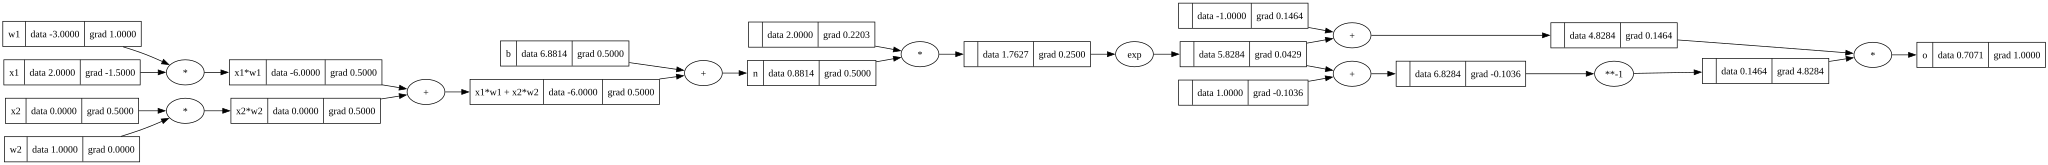

In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# ----
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ----
o.label = 'o'
o.backward()
draw_dot(o)

# t = e^ (2(x1*w1 + x2*w2 + b))
# y = (t-1) / (t+1)